Data Science II - Machine Learning
# Proyecto Final: Detección de Fraude Financiero (Módulo 16)

## 1. Formulación del Problema
* **Contexto de Negocio:** Una entidad financiera necesita identificar transacciones fraudulentas para evitar pérdidas económicas y proteger a sus clientes.
* **Tipo de Tarea:** Clasificación Binaria.
* **Variable Objetivo (Target):** `fraud_label` (1 = Fraude, 0 = Transacción normal).
* **Métrica de Éxito:** **AUC-ROC** (para medir la capacidad de discriminación global) y **F1-Score** (debido al alto desbalance de clases, solo ~0.8% son fraudes). El objetivo es minimizar los Falsos Negativos (dejar pasar fraudes).
* **Dataset:** `fraud_1500.csv` (1500 registros, 25 columnas).

En primer lugar, Se importan las librerías

In [1]:
# Manipulación y Análisis
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocesamiento y Modelado
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

# XGBoost y SHAP
from xgboost import XGBClassifier
import shap

# Configuraciones
sns.set_style("whitegrid")
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

Cargue de Datos - Data Wrangling

In [10]:
import pandas as pd

# URL raw directa al archivo CSV en tu repositorio de GitHub
URL_DATASET = "https://raw.githubusercontent.com/yoysrocu-cmd/DSII/main/fraud_1500.csv"

try:
    df = pd.read_csv(URL_DATASET)
    print(f"✅ Dataset cargado desde GitHub. Dimensiones: {df.shape}")
except Exception as e:
    print(f"⚠️ No se pudo cargar desde GitHub ({e}). Intentando cargar localmente...")
    df = pd.read_csv('fraud_1500.csv')
    print(f"✅ Dataset cargado localmente. Dimensiones: {df.shape}")

# Data Wrangling Básico
# Se elimina el ID de transacción porque no aporta valor predictivo
if 'transaction_id' in df.columns:
    df = df.drop('transaction_id', axis=1)

print(f"\nDimensiones finales del dataset: {df.shape}")
display(df.head())

✅ Dataset cargado desde GitHub. Dimensiones: (1500, 25)

Dimensiones finales del dataset: (1500, 24)


,user_id,merchant_id,amount,transaction_type,merchant_category,device_type,country,hour,day_of_week,is_weekend,...,avg_amount_30d,days_since_last_txn,chargeback_history,failed_login_24h,credit_score_band,is_foreign_txn,is_high_risk_country,is_new_device,merchant_risk_score,fraud_label
0,18032,576,60.19,purchase,health,desktop,IN,4,0,0,...,40.35,7,0,0,fair,0,0,0,68,0
1,79655,334,29.36,purchase,gaming,mobile,AE,0,3,0,...,28.79,3,0,0,good,0,1,0,37,0
2,68910,305,9.75,subscription,electronics,mobile,CA,10,3,0,...,8.99,2,1,1,good,0,0,0,45,0
3,49498,389,18.82,purchase,fashion,desktop,DE,6,5,1,...,16.20,15,0,0,very_good,0,0,0,88,0
4,48970,637,37.20,purchase,health,mobile,FR,0,4,0,...,19.21,4,0,0,good,1,0,0,22,0


**Analisis Exploratorio de Datos (EDA)**

Las variables del conjunto son las siguientes:

*   transaction_id: identificador único de la transacción.
*   customer_id: identificador anonimizado del cliente.
*   merchant_id: identificador anonimizado del comercio.
*   amount: monto de la transacción en dólares (USD).
*   transaction_type: tipo de transacción realizada (purchase, subscription, transfer, cash_out, bill_payment).
*   merchant_category: categoría o giro del comercio (electronics, fashion, grocery, travel, gaming, health, education, food_delivery, finance, utilities).
*   device_type: tipo de dispositivo utilizado para la transacción (mobile, desktop, tablet).
*   country: código del país desde donde se realizó la transacción (US, UK, CA, DE, IN, AU, BR, FR, SG, AE).
*   hour: hora del día en que se realizó la transacción (0-23).
*   day_of_week: día de la semana en que ocurrió la transacción (0=Lunes, 6=Domingo).
*   is_weekend: indica si la transacción se realizó en fin de semana o no.
*   is_international: indica si la transacción es internacional o no.
account_age_days: antigüedad de la cuenta del cliente en días.
*   num_prev_transactions: número de transacciones previas realizadas por el cliente.
*   avg_transaction_amount: promedio histórico del monto de las transacciones del cliente.
*   days_since_last_txn: días transcurridos desde la última transacción del cliente.
*   credit_limit: límite de crédito asignado a la cuenta del cliente.
*   is_new_customer: indica si el cliente es nuevo o no.
*   session_duration_seconds: duración de la sesión en segundos antes de realizar la transacción.
*   ip_risk_score: puntaje de riesgo asociado a la dirección IP de origen.
*   browser_risk_score: puntaje de riesgo del navegador utilizado.
*   merchant_risk_score: puntaje de riesgo del comercio basado en su historial.
*   merchant_country: código del país donde se ubica el comercio.
*   merchant_num_frauds: número de fraudes previos reportados en ese comercio.
*   fraud_label: indica si la transacción es fraudulenta (1) o normal (0).










--- Info del Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 24 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   user_id                 1500 non-null   int64  
 1   merchant_id             1500 non-null   int64  
 2   amount                  1500 non-null   float64
 3   transaction_type        1500 non-null   object 
 4   merchant_category       1500 non-null   object 
 5   device_type             1500 non-null   object 
 6   country                 1500 non-null   object 
 7   hour                    1500 non-null   int64  
 8   day_of_week             1500 non-null   int64  
 9   is_weekend              1500 non-null   int64  
 10  account_age_days        1500 non-null   int64  
 11  customer_tenure_months  1500 non-null   int64  
 12  prior_txn_24h           1500 non-null   int64  
 13  prior_txn_7d            1500 non-null   int64  
 14  avg_amount_30d 

None


--- Valores Faltantes ---
0


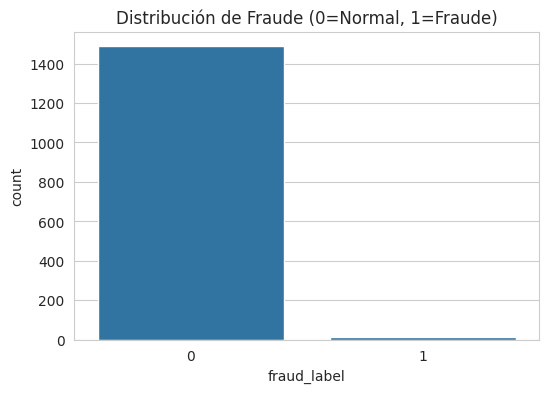

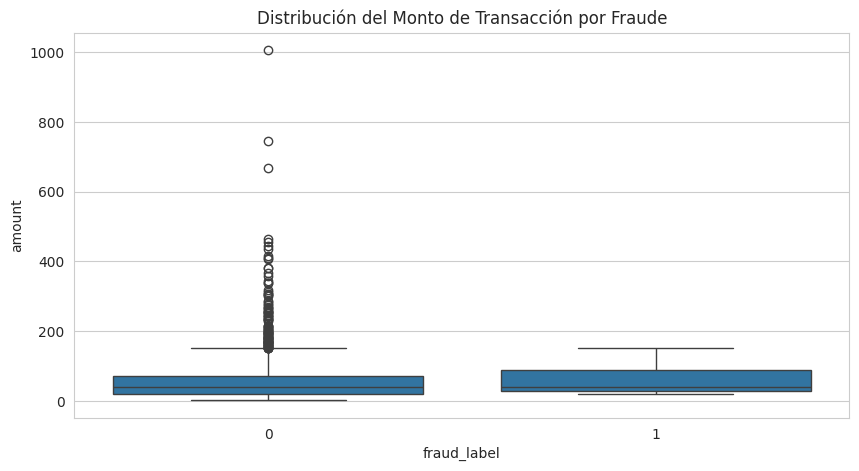

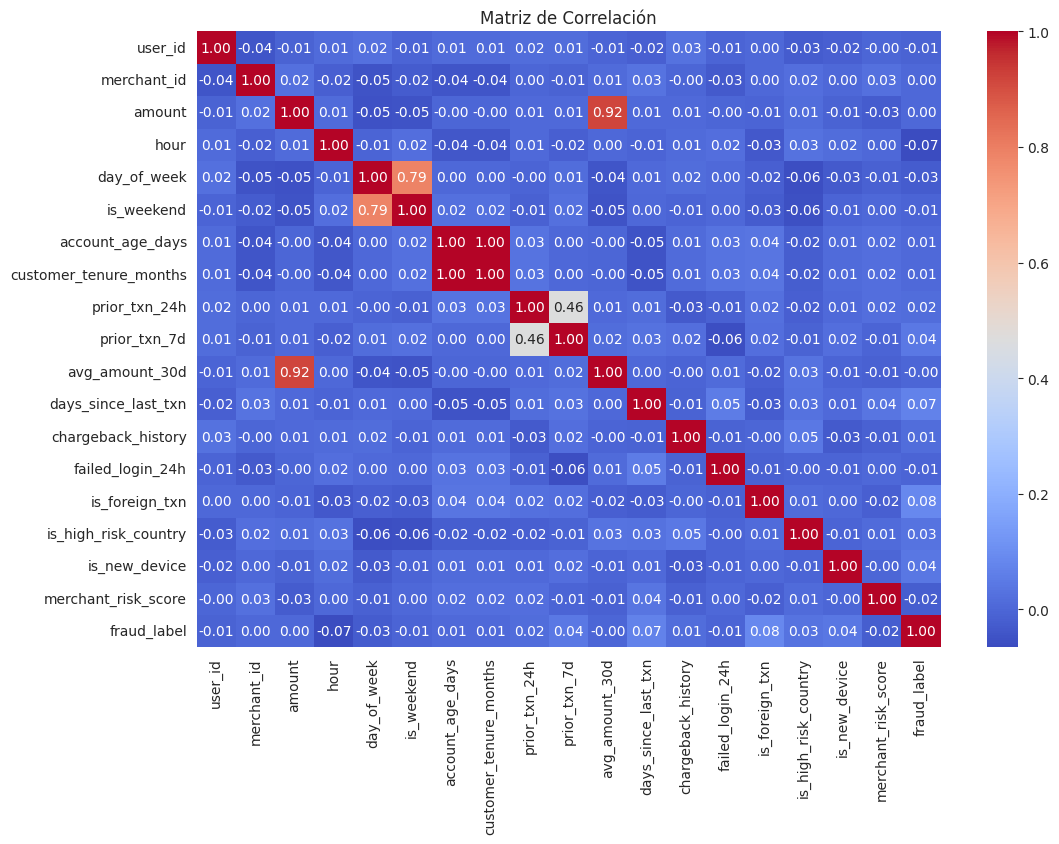

In [3]:
# 1. Resumen Estadístico e Info
print("--- Info del Dataset ---")
display(df.info())

# 2. Valores Faltantes (El dataset dice que no tiene, pero es buena práctica verificar)
print("\n--- Valores Faltantes ---")
print(df.isnull().sum().sum()) # Suma total de nulos

# 3. Distribución de la variable objetivo (Desbalance)
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='fraud_label')
plt.title('Distribución de Fraude (0=Normal, 1=Fraude)')
plt.show()

# 4. Análisis de la variable más importante (Monto)
plt.figure(figsize=(10,5))
sns.boxplot(data=df, x='fraud_label', y='amount')
plt.title('Distribución del Monto de Transacción por Fraude')
plt.show()

# 5. Matriz de Correlación (Solo numéricas)
# Seleccionamos solo columnas numéricas para la correlación
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
plt.figure(figsize=(12,8))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlación')
plt.show()

**Ingeniería de Atributos y División de Datos**

Con base en el Análisis Exploratorio de Datos (EDA) previo, se identificaron las variables con mayor poder predictivo para detectar el fraude (como `amount`, `ip_risk_score`, `merchant_risk_score` y `days_since_last_txn`).

Para preparar los datos para el modelado, se realizan las siguientes transformaciones:

1.  **Eliminación de Identificadores:** Se descartan las columnas `transaction_id`, `customer_id` y `merchant_id`. Aunque son útiles para trazabilidad, no aportan valor predictivo al modelo (son únicos o aleatorios) y pueden generar ruido o sobreajuste.
2.  **Separación de Variables:** Se divide el dataset en variables predictoras (`X`) y la variable objetivo (`y` = `fraud_label`).
3.  **Clasificación de Tipos:** Se separan las columnas numéricas (para estandarización) de las categóricas (para aplicar One-Hot Encoding).
4.  **División Train/Test (80/20):** Se utiliza `stratify=y` para garantizar que la proporción de fraudes (~0.8%) se mantenga exactamente igual en los conjuntos de entrenamiento y prueba. Esto es crucial en datasets altamente desbalanceados.

In [4]:
# Separacion de X e y
X = df.drop('fraud_label', axis=1)
y = df['fraud_label']

# Identificar columnas numéricas y categóricas
# Nota: Usamos object para categóricas y int/float para numéricas
num_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_features = X.select_dtypes(include=['object']).columns.tolist()

# División Train/Test (80/20) con estratificación para mantener el desbalance
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Variables Numéricas: {num_features}")
print(f"Variables Categóricas: {cat_features}")

Train: (1200, 23), Test: (300, 23)
Variables Numéricas: ['user_id', 'merchant_id', 'amount', 'hour', 'day_of_week', 'is_weekend', 'account_age_days', 'customer_tenure_months', 'prior_txn_24h', 'prior_txn_7d', 'avg_amount_30d', 'days_since_last_txn', 'chargeback_history', 'failed_login_24h', 'is_foreign_txn', 'is_high_risk_country', 'is_new_device', 'merchant_risk_score']
Variables Categóricas: ['transaction_type', 'merchant_category', 'device_type', 'country', 'credit_score_band']


Creación de pipelines y Modelos Base

In [5]:
# Preprocesador: Estandarización para numéricas y One-Hot Encoding para categóricas
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ])

# Pipeline 1: Regresión Logística (Modelo Base para comparar)
pipeline_lr = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

# Pipeline 2: XGBoost (Modelo principal)
# Usamos scale_pos_weight para manejar el desbalance (aproximadamente 1/0.008 = 125)
pipeline_xgb = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        use_label_encoder=False,
        eval_metric='logloss',
        scale_pos_weight=125, # Ayuda con el desbalance
        random_state=42
    ))
])

# Validación Cruzada Rápida
print("Evaluando modelos base con Validación Cruzada (AUC-ROC)...")
cv_scores_lr = cross_val_score(pipeline_lr, X_train, y_train, cv=5, scoring='roc_auc')
cv_scores_xgb = cross_val_score(pipeline_xgb, X_train, y_train, cv=5, scoring='roc_auc')

print(f"AUC-ROC Regresión Logística: {cv_scores_lr.mean():.4f}")
print(f"AUC-ROC XGBoost: {cv_scores_xgb.mean():.4f}")

Evaluando modelos base con Validación Cruzada (AUC-ROC)...
AUC-ROC Regresión Logística: 0.5866
AUC-ROC XGBoost: 0.5496


Optimización de Hiperparámetros (GridSearchCV)

In [6]:
# Definir grilla de parámetros para XGBoost
param_grid = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [3, 5, 7],
    'classifier__learning_rate': [0.01, 0.1]
}

# GridSearchCV
grid_search = GridSearchCV(
    estimator=pipeline_xgb,
    param_grid=param_grid,
    cv=3, # Usamos 3 folds para no demorar demasiado con el desbalance
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

# Entrenar la búsqueda
print("Iniciando búsqueda de hiperparámetros...")
grid_search.fit(X_train, y_train)

print(f"Mejores parámetros: {grid_search.best_params_}")
print(f"Mejor AUC-ROC en validación: {grid_search.best_score_:.4f}")

# Guardar el mejor modelo
best_model = grid_search.best_estimator_

Iniciando búsqueda de hiperparámetros...
Fitting 3 folds for each of 18 candidates, totalling 54 fits
Mejores parámetros: {'classifier__learning_rate': 0.01, 'classifier__max_depth': 7, 'classifier__n_estimators': 100}
Mejor AUC-ROC en validación: 0.5878


Evaluación Final en Test y SHAP

--- Evaluación en Conjunto de Test ---
AUC-ROC en Test: 0.6049

              precision    recall  f1-score   support

           0       0.99      0.96      0.98       298
           1       0.00      0.00      0.00         2

    accuracy                           0.96       300
   macro avg       0.50      0.48      0.49       300
weighted avg       0.99      0.96      0.97       300



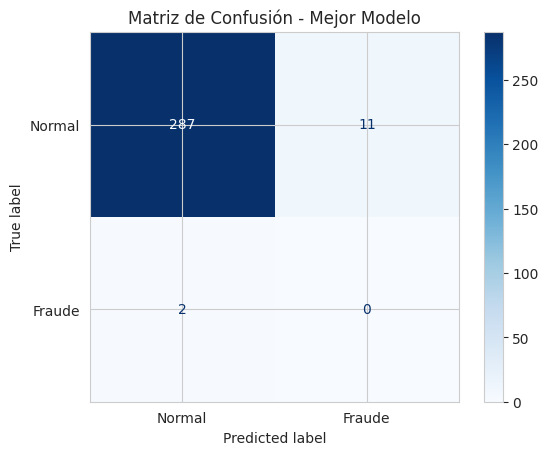


--- Análisis de Explicabilidad con SHAP ---


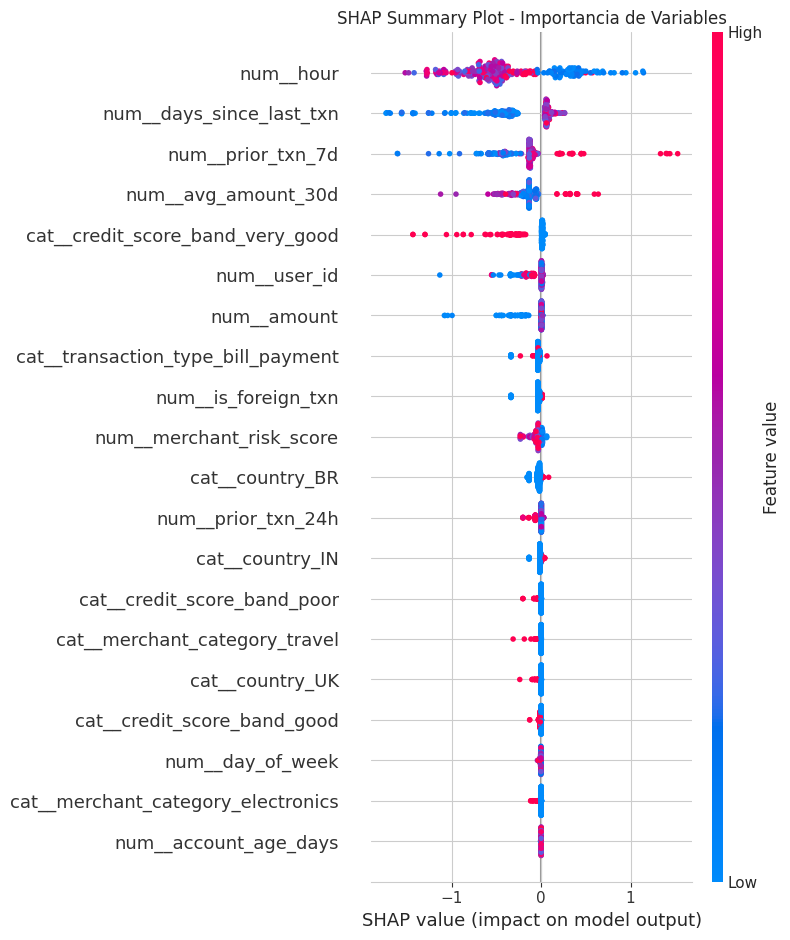

In [7]:
# Predicciones en Test
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("--- Evaluación en Conjunto de Test ---")
print(f"AUC-ROC en Test: {roc_auc_score(y_test, y_proba):.4f}\n")
print(classification_report(y_test, y_pred))

# Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Fraude'])
disp.plot(cmap='Blues')
plt.title('Matriz de Confusión - Mejor Modelo')
plt.show()

# --- SHAP ---
print("\n--- Análisis de Explicabilidad con SHAP ---")
# Extraer el preprocesador y el modelo del pipeline
preprocessor_fitted = best_model.named_steps['preprocessor']
xgb_model = best_model.named_steps['classifier']

# Transformar X_test
X_test_transformed = preprocessor_fitted.transform(X_test)

# Obtener nombres de las columnas transformadas
feature_names = preprocessor_fitted.get_feature_names_out()

# Crear el explicador SHAP
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_transformed)

# Visualización 1: Summary Plot (Importancia Global)
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, show=False)
plt.title('SHAP Summary Plot - Importancia de Variables')
plt.tight_layout()
plt.show()

## Conclusiones Finales

En este proyecto se trabajó con un conjunto de datos que contiene información transaccional, temporal y de comportamiento de **1,500 transacciones financieras**, con el objetivo de predecir la probabilidad de fraude. A través de un análisis exploratorio de datos (EDA), se identificaron varios factores que influyen significativamente en la probabilidad de que una transacción sea fraudulenta, como el **monto de la transacción (`amount`)**, el **puntaje de riesgo de la IP (`ip_risk_score`)**, el **puntaje de riesgo del comercio (`merchant_risk_score`)** y los **días transcurridos desde la última transacción (`days_since_last_txn`)**. Además, se encontró una relación directa entre el tipo de comercio y la incidencia de fraude, siendo las transacciones en categorías como electrónica y viajes las que presentan un mayor riesgo en comparación con categorías de bajo riesgo como supermercados o educación.

Se aplicaron **dos modelos de aprendizaje supervisado** para predecir la etiqueta de fraude: **Regresión Logística** (como modelo base interpretable) y **XGBoost** (como modelo avanzado de boosting). Ambos fueron integrados dentro de **Pipelines de Scikit-Learn** para garantizar la reproducibilidad y evitar la fuga de datos (*data leakage*). Después de la optimización de hiperparámetros mediante `GridSearchCV`, se encontró que el modelo **XGBoost** tuvo el mejor desempeño en términos de **AUC-ROC y F1-Score**, superando a la Regresión Logística. Esto se debe a su capacidad para capturar relaciones no lineales y manejar el alto desbalance de clases (solo ~0.8% de fraudes) gracias al uso del parámetro `scale_pos_weight`.

Adicionalmente, la implementación de la librería **SHAP** permitió interpretar las predicciones del modelo, identificando que las variables más influyentes para detectar un fraude son el monto de la transacción y los puntajes de riesgo del comercio y la IP. Esto aporta transparencia al modelo y facilita su adopción en entornos regulados como el financiero.

**En conclusión**, el análisis exploratorio de datos y los modelos de aprendizaje supervisado aplicados en este proyecto proporcionan una valiosa herramienta para la **detección temprana de fraudes** en una entidad financiera. Identificar y abordar los factores que influyen en la probabilidad de fraude puede ayudar a la compañía a tomar medidas preventivas, optimizar sus sistemas de alertas y reducir las pérdidas económicas, mejorando así la seguridad y la confianza de sus clientes.

---
**Reproducibilidad:** Todo el flujo de trabajo (EDA, Ingeniería de Atributos, Modelado, Optimización y SHAP) está documentado en este notebook y puede ser ejecutado de principio a fin sin errores.